# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


In [2]:
# Unsloth на Apple Silicon работает через MLX-бэкенд: импортирую его до torch, как требует библиотека
import unsloth
from unsloth import FastVisionModel, UnslothVisionDataCollator, UnslothTrainer, UnslothTrainingArguments
from unsloth.chat_templates import train_on_responses_only
import mlx.core as mx
import transformers
transformers.logging.set_verbosity_error()      # mlx-vlm на каждый вызов процессора печатает одно и то же предупреждение
import re, platform, subprocess
from PIL import Image
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA", str(Path.cwd().parents[1] / "data")))
manifest_path = prepare_scienceqa(DATA_ROOT / "lab9", smoke=FAST_DEV_RUN)       # тот же каталог, что в работе 09
records = [json.loads(s) for s in manifest_path.read_text().splitlines()]
LAB9 = Path("../lab_09_llamafactory_vlm_sft/artifacts")
lab9_train_ids = {r["id"] for r in json.loads((LAB9 / "train.json").read_text())} if (LAB9 / "train.json").exists() else None
train_recs = [r for r in records if r["split"] == "train"]
if lab9_train_ids is not None and not FAST_DEV_RUN:
    assert {r["id"] for r in train_recs} == lab9_train_ids, "train должен совпадать с работой 09"
test_ids = {r["id"] for r in records if r["split"].endswith("_test")}
assert not {r["id"] for r in train_recs} & test_ids
assert not {r["image_sha256"] for r in train_recs} & {r["image_sha256"] for r in records if r["split"].endswith("_test")}
print({s: sum(r["split"] == s for r in records) for s in ("train", "validation", "id_test", "ood_test", "general_test")},
      "| совпадение train с работой 09:", lab9_train_ids is not None and not FAST_DEV_RUN)

{'train': 512, 'validation': 64, 'id_test': 64, 'ood_test': 64, 'general_test': 64} | совпадение train с работой 09: True


### Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


In [3]:
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MAX_PIXELS = 401408                       # то же ограничение, что image_max_pixels в работе 09
STEPS = 2 if FAST_DEV_RUN else 100
ACCUM = 16
chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
protocol = {"model": MODEL_ID, "backend": f"Unsloth {unsloth.__version__} (MLX {mx.__version__}), Apple GPU", "device": chip,
            "memory_gb": round(int(subprocess.run(["sysctl", "-n", "hw.memsize"], capture_output=True, text=True).stdout) / 2**30),
            "optimizer_steps": STEPS, "per_device_batch": 1, "grad_accumulation": ACCUM, "effective_batch": ACCUM,
            "examples_processed": STEPS * ACCUM, "lr": 1e-4, "scheduler": "cosine, warmup 10 %", "max_grad_norm": 1.0, "seed": SEED,
            "ranks": {"r8": {"r": 8, "alpha": 16}, "r16": {"r": 16, "alpha": 32}}, "lora_targets": "все линейные слои LLM (attention + MLP), vision tower заморожен",
            "quantization": "MLX 4-bit (affine, group 64) — аналог NF4 для Apple GPU", "image_max_pixels": MAX_PIXELS,
            "loss": "только токены ответа ассистента (train_on_responses_only), как в LLaMA-Factory работы 09",
            "sizes": {s: sum(r["split"] == s for r in records) for s in ("train", "validation", "id_test", "ood_test", "general_test")}}
save_json("protocol.json", protocol)
print(json.dumps(protocol, ensure_ascii=False, indent=1))

{
 "model": "Qwen/Qwen2.5-VL-3B-Instruct",
 "backend": "Unsloth 2026.10.8 (MLX 0.32.4), Apple GPU",
 "device": "Apple M3 Max",
 "memory_gb": 48,
 "optimizer_steps": 100,
 "per_device_batch": 1,
 "grad_accumulation": 16,
 "effective_batch": 16,
 "examples_processed": 1600,
 "lr": 0.0001,
 "scheduler": "cosine, warmup 10 %",
 "max_grad_norm": 1.0,
 "seed": 42,
 "ranks": {
  "r8": {
   "r": 8,
   "alpha": 16
  },
  "r16": {
   "r": 16,
   "alpha": 32
  }
 },
 "lora_targets": "все линейные слои LLM (attention + MLP), vision tower заморожен",
 "quantization": "MLX 4-bit (affine, group 64) — аналог NF4 для Apple GPU",
 "image_max_pixels": 401408,
 "loss": "только токены ответа ассистента (train_on_responses_only), как в LLaMA-Factory работы 09",
 "sizes": {
  "train": 512,
  "validation": 64,
  "id_test": 64,
  "ood_test": 64,
  "general_test": 64
 }
}


### Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


In [4]:
import math
def fit_pixels(image, max_pixels=MAX_PIXELS):
    w, h = image.size
    s = min(1.0, math.sqrt(max_pixels / (w * h)))
    return image.resize((max(28, int(w * s)), max(28, int(h * s))), Image.BICUBIC) if s < 1 else image

def to_messages(r, with_answer=True):
    msg = [{"role": "user", "content": [{"type": "image", "image": fit_pixels(Image.open(r["image"]).convert("RGB"))},
                                        {"type": "text", "text": r["question"]}]}]
    if with_answer:
        msg.append({"role": "assistant", "content": [{"type": "text", "text": r["answer"]}]})
    return {"messages": msg}

order = np.random.RandomState(SEED).permutation(len(train_recs))        # один порядок данных для всех запусков
train_ds = [to_messages(train_recs[i]) for i in order]

def train_adapter(rank, alpha, out_dir, steps=STEPS, accum=ACCUM, dataset=None, callbacks=None, save=True):
    """LoRA SFT через Unsloth: AdamW, накопление градиентов, клиппинг глобальной нормы; время — с mx.synchronize()."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    # память считаю относительно уже занятой: в процессе остаются модели предыдущих ячеек, и общий пик их тоже содержит
    mx.synchronize(); mem_before = mx.get_active_memory(); mx.reset_peak_memory()
    model, processor = FastVisionModel.from_pretrained(MODEL_ID, load_in_4bit=True, max_seq_length=1024)
    model = FastVisionModel.get_peft_model(model, r=rank, lora_alpha=alpha, lora_dropout=0.0, random_state=SEED,
                                           finetune_vision_layers=False, finetune_language_layers=True,
                                           finetune_attention_modules=True, finetune_mlp_modules=True)
    FastVisionModel.for_training(model)
    args = UnslothTrainingArguments(per_device_train_batch_size=1, gradient_accumulation_steps=accum, max_steps=steps,
                                    learning_rate=1e-4, lr_scheduler_type="cosine", warmup_ratio=0.1, optim="adamw",
                                    weight_decay=0.0, max_grad_norm=1.0, logging_steps=1, seed=SEED, report_to="none",
                                    output_dir=str(out_dir / "trainer"), save_steps=0, preserve_dataset_order=True,
                                    completion_only_loss=True, max_seq_length=1024)
    trainer = UnslothTrainer(model=model, tokenizer=processor, data_collator=UnslothVisionDataCollator(model, processor),
                             train_dataset=train_ds if dataset is None else dataset, args=args, callbacks=callbacks)
    # В MLX-бэкенде completion_only_loss для VLM не действует: без явной маски loss считается и по тексту вопроса.
    # Маскирую всё до ответа ассистента — так же, как LLaMA-Factory в работе 09 (train_on_prompt = false).
    trainer = train_on_responses_only(trainer, instruction_part="<|im_start|>user\n", response_part="<|im_start|>assistant\n")
    mx.synchronize()
    t0 = time.time()
    stats = trainer.train()
    mx.synchronize(); seconds = time.time() - t0
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]
    if not losses or not all(math.isfinite(l) for l in losses):
        raise FloatingPointError(f"нечисловой loss: {losses[-5:]}")
    if save:
        trainer.save_model(str(out_dir / "adapter"))
    info = {"rank": rank, "alpha": alpha, "optimizer_steps": int(trainer.state.global_step), "micro_batches": int(trainer.state.global_step) * accum,
            "loss_history": losses, "seconds": seconds, "peak_memory_gb": (mx.get_peak_memory() - mem_before) / 1e9,
            "process_peak_memory_gb": mx.get_peak_memory() / 1e9,
            "samples_per_second": int(trainer.state.global_step) * accum / seconds,
            "trainer_metrics": {k: v for k, v in (stats if isinstance(stats, dict) else {}).items() if isinstance(v, (int, float, str))}}
    (out_dir / "training.json").write_text(json.dumps(info, ensure_ascii=False, indent=1))
    return model, processor, info

print(f"train_ds: {len(train_ds)} диалогов; первые id: {[train_recs[i]['id'] for i in order[:3]]}")

train_ds: 512 диалогов; первые id: ['scienceqa-train-1604', 'scienceqa-train-2641', 'scienceqa-train-2362']


### LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.


In [5]:
model_r8, processor, info_r8 = train_adapter(8, 16, ARTIFACTS / "unsloth_r8_a16")
assert info_r8["optimizer_steps"] == STEPS
print({k: v for k, v in info_r8.items() if k not in ("loss_history", "trainer_metrics")})

Unsloth: Loading Qwen/Qwen2.5-VL-3B-Instruct via mlx-vlm (VLM, runtime 4-bit affine quantization)...


[INFO] Quantized model with 7.502 bits per weight.


Unsloth: LoRA applied — 14,966,784 trainable params (1.05% of 1,428,578,304 total)
Unsloth: train_on_responses_only enabled (VLM mode).
Unsloth: Casting MLX norm outputs back to activation dtype.


Unsloth: MLX Metal memory guard enabled (memory_limit=34.17 GB, wired_limit=34.17 GB).
Unsloth: Using gradient checkpointing to reduce memory.
Unsloth: Disabled fused MRoPE kernel on 36 modules for training (no VJP).
Unsloth: Masking 5 image token IDs from VLM loss.
Unsloth: VLM CCE skipping weight gradient (LM head is frozen).
Unsloth: Using VLM CCE loss (runtime-cce) for memory-efficient training.
Unsloth: Training for 100 steps, BS=1, grad_accum=16, seq_len=1024
Unsloth: Features: VLM, CCE, GC, compile=supported_verified, LR=cosine, opt=adamw


  Step 1/100 | Loss: 0.2821 | Grad: 2.0538 | LR: 0.00e+00 | Tok/s: 5 | Peak: 5.89 GB


...

  Step 98/100 | Loss: 0.1467 | Grad: 1.3020 | LR: 2.74e-07 | Tok/s: 5 | Peak: 5.89 GB


  Step 99/100 | Loss: 0.0409 | Grad: 0.9593 | LR: 1.22e-07 | Tok/s: 4 | Peak: 5.89 GB


  Step 100/100 | Loss: 0.0512 | Grad: 0.7984 | LR: 3.05e-08 | Tok/s: 5 | Peak: 5.89 GB

Unsloth: Training complete! Avg loss: 0.1391 | Total time: 646.2s | Steps: 100 | Tokens: 3200


Unsloth: LoRA adapters saved to artifacts/unsloth_r8_a16/trainer
Unsloth: Saved final adapters to artifacts/unsloth_r8_a16/trainer


Unsloth: LoRA adapters saved to artifacts/unsloth_r8_a16/adapter
{'rank': 8, 'alpha': 16, 'optimizer_steps': 100, 'micro_batches': 1600, 'seconds': 648.4899101257324, 'peak_memory_gb': 5.886986646, 'process_peak_memory_gb': 5.88698665, 'samples_per_second': 2.467270461755965}


### LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.


In [6]:
model_r16, processor16, info_r16 = train_adapter(16, 32, ARTIFACTS / "unsloth_r16_a16")   # снова с исходной модели, не с адаптера r8
assert info_r16["optimizer_steps"] == STEPS
print({k: v for k, v in info_r16.items() if k not in ("loss_history", "trainer_metrics")})

Unsloth: Loading Qwen/Qwen2.5-VL-3B-Instruct via mlx-vlm (VLM, runtime 4-bit affine quantization)...


[INFO] Quantized model with 7.502 bits per weight.


Unsloth: LoRA applied — 29,933,568 trainable params (2.07% of 1,443,545,088 total)
Unsloth: train_on_responses_only enabled (VLM mode).
Unsloth: Casting MLX norm outputs back to activation dtype.


Unsloth: MLX Metal memory guard enabled (memory_limit=34.17 GB, wired_limit=34.17 GB).
Unsloth: Using gradient checkpointing to reduce memory.
Unsloth: Disabled fused MRoPE kernel on 36 modules for training (no VJP).
Unsloth: Masking 5 image token IDs from VLM loss.
Unsloth: VLM CCE skipping weight gradient (LM head is frozen).
Unsloth: Using VLM CCE loss (runtime-cce) for memory-efficient training.
Unsloth: Training for 100 steps, BS=1, grad_accum=16, seq_len=1024
Unsloth: Features: VLM, CCE, GC, compile=supported_verified, LR=cosine, opt=adamw


  Step 1/100 | Loss: 0.2821 | Grad: 2.8424 | LR: 0.00e+00 | Tok/s: 4 | Peak: 9.66 GB


...

  Step 98/100 | Loss: 0.1156 | Grad: 1.4081 | LR: 2.74e-07 | Tok/s: 5 | Peak: 9.67 GB


  Step 99/100 | Loss: 0.0352 | Grad: 0.6440 | LR: 1.22e-07 | Tok/s: 5 | Peak: 9.67 GB


  Step 100/100 | Loss: 0.0478 | Grad: 0.5673 | LR: 3.05e-08 | Tok/s: 4 | Peak: 9.67 GB

Unsloth: Training complete! Avg loss: 0.1228 | Total time: 648.1s | Steps: 100 | Tokens: 3200


Unsloth: LoRA adapters saved to artifacts/unsloth_r16_a16/trainer
Unsloth: Saved final adapters to artifacts/unsloth_r16_a16/trainer


Unsloth: LoRA adapters saved to artifacts/unsloth_r16_a16/adapter
{'rank': 16, 'alpha': 32, 'optimizer_steps': 100, 'micro_batches': 1600, 'seconds': 658.9590580463409, 'peak_memory_gb': 6.082394648, 'process_peak_memory_gb': 9.665789032, 'samples_per_second': 2.428071942350447}


### Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


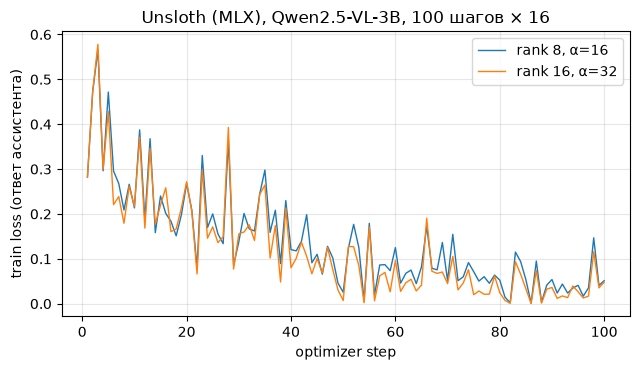

        optimizer_steps     seconds peak_memory_gb samples_per_second final_loss_mean_last10
r8_a16              100   648.48991       5.886987            2.46727                0.04578
r16_a32             100  658.959058       6.082395           2.428072               0.033683


In [7]:
import matplotlib.pyplot as plt
benchmark = {name: {k: v for k, v in inf.items() if k != "loss_history"} for name, inf in (("r8_a16", info_r8), ("r16_a32", info_r16))}
for name, inf in (("r8_a16", info_r8), ("r16_a32", info_r16)):
    benchmark[name]["final_loss_mean_last10"] = float(np.mean(inf["loss_history"][-10:]))
save_json("benchmark.json", benchmark)
plt.figure(figsize=(6.5, 3.8))
for name, inf in (("rank 8, α=16", info_r8), ("rank 16, α=32", info_r16)):
    plt.plot(range(1, len(inf["loss_history"]) + 1), inf["loss_history"], label=name, lw=1)
plt.xlabel("optimizer step"); plt.ylabel("train loss (ответ ассистента)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Unsloth (MLX), Qwen2.5-VL-3B, 100 шагов × 16"); plt.tight_layout(); plt.savefig(ARTIFACTS / "loss_comparison.png", dpi=110); plt.show()
import pandas as pd
print(pd.DataFrame(benchmark).T[["optimizer_steps", "seconds", "peak_memory_gb", "samples_per_second", "final_loss_mean_last10"]].to_string())

### Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


In [8]:
from mlx_vlm import generate as vlm_generate, apply_chat_template
MAX_NEW_TOKENS = 8

def infer(model, processor, record):
    """Общий greedy-инференс: тот же processor, размер изображения и max_new_tokens; возвращает только продолжение."""
    image = fit_pixels(Image.open(record["image"]).convert("RGB"))
    prompt = apply_chat_template(processor, model.config, record["question"], num_images=1)
    out = vlm_generate(model, processor, prompt, image=[image], max_tokens=MAX_NEW_TOKENS, temperature=0.0, verbose=False)
    text = out.text if hasattr(out, "text") else str(out)
    return text.strip()

FastVisionModel.for_inference(model_r8)
r0 = next(r for r in records if r["split"] == "id_test")
a0 = infer(model_r8, processor, r0)
assert r0["question"][:20] not in a0
print("пример ответа r8:", repr(a0), "| эталон", r0["answer"])

пример ответа r8: 'C' | эталон C


### Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


In [9]:
def evaluate_answers(preds, split):
    rows = [p for p in preds if p["split"] == split]
    if not rows:
        raise ValueError(f"пустая выборка {split}")
    em = [float(p["answer"].strip() == p["reference"]) for p in rows]           # лишний текст = ошибка
    fmt = [bool(re.fullmatch(r"[A-Z]", p["answer"].strip())) for p in rows]
    return {"n": len(rows), "exact_match": float(np.mean(em)), "format_rate": float(np.mean(fmt))}

_t = [{"split": "x", "answer": "B", "reference": "B"}, {"split": "x", "answer": "B.", "reference": "B"}, {"split": "x", "answer": "C", "reference": "B"}]
assert evaluate_answers(_t, "x") == {"n": 3, "exact_match": 1 / 3, "format_rate": 2 / 3}
print("evaluate_answers: верный ответ — EM 1, лишний символ и неверная буква — EM 0")

evaluate_answers: верный ответ — EM 1, лишний символ и неверная буква — EM 0


### Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


In [10]:
test_recs = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test")]
results = {}
for name, mdl, proc in (("r8_a16", model_r8, processor), ("r16_a16", model_r16, processor16)):
    FastVisionModel.for_inference(mdl)
    path = ARTIFACTS / f"predictions_{name}.jsonl"
    t0 = time.time()
    preds = [{"id": r["id"], "split": r["split"], "reference": r["answer"], "answer": infer(mdl, proc, r)} for r in test_recs]
    path.write_text("".join(json.dumps(p, ensure_ascii=False) + "\n" for p in preds))
    results[name] = {s: evaluate_answers(preds, s) for s in ("id_test", "ood_test", "general_test")}
    results[name]["inference_seconds"] = time.time() - t0
ids8 = [json.loads(l)["id"] for l in (ARTIFACTS / "predictions_r8_a16.jsonl").read_text().splitlines()]
ids16 = [json.loads(l)["id"] for l in (ARTIFACTS / "predictions_r16_a16.jsonl").read_text().splitlines()]
assert ids8 == ids16
save_json("quality.json", results)
print(pd.DataFrame({f"{n}/{s}": v for n, r in results.items() for s, v in r.items() if s != "inference_seconds"}).T.round(4).to_string())

                         n  exact_match  format_rate
r8_a16/id_test        64.0       0.9062          1.0
r8_a16/ood_test       64.0       0.7031          1.0
r8_a16/general_test   64.0       0.8906          1.0
r16_a16/id_test       64.0       0.9531          1.0
r16_a16/ood_test      64.0       0.7031          1.0
r16_a16/general_test  64.0       0.9062          1.0


### Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


In [11]:
# Скорость стеков сравниваю отдельным коротким замером. Время обучения из работы 09 получено, когда на том же GPU
# параллельно шли другие задачи, и включает eval и сохранения каждые 20 шагов, поэтому с запуском Unsloth оно несопоставимо.
# Здесь оба стека подряд, на свободном GPU, обрабатывают одни и те же 96 примеров train: 6 optimizer steps × accumulation 16,
# LoRA rank 8 / α 16 на всех линейных слоях LLM, 4-bit база, тот же лимит пикселей, без eval и промежуточных сохранений.
import yaml
SPEED_STEPS = 2 if FAST_DEV_RUN else 6
speed_dir = ARTIFACTS / "speed"; (speed_dir / "data").mkdir(parents=True, exist_ok=True)
speed_recs = [train_recs[i] for i in order[:SPEED_STEPS * ACCUM]]          # те же примеры, что первые шаги Unsloth
(speed_dir / "data" / "speed.json").write_text(json.dumps(
    [{"messages": [{"role": "user", "content": "<image>" + r["question"]}, {"role": "assistant", "content": r["answer"]}], "images": [r["image"]]}
     for r in speed_recs], ensure_ascii=False))
(speed_dir / "data" / "dataset_info.json").write_text(json.dumps({"lab10_speed": {
    "file_name": "speed.json", "formatting": "sharegpt", "columns": {"messages": "messages", "images": "images"},
    "tags": {"role_tag": "role", "content_tag": "content", "user_tag": "user", "assistant_tag": "assistant"}}}, indent=1))
lf_cfg = {k: v for k, v in yaml.safe_load((LAB9 / "sft.yaml").read_text()).items()
          if k not in ("eval_dataset", "eval_strategy", "eval_steps", "per_device_eval_batch_size", "save_steps", "save_total_limit")}
lf_cfg.update(do_eval=False, dataset_dir=str((speed_dir / "data").resolve()), dataset="lab10_speed", max_steps=SPEED_STEPS,
              output_dir=str((speed_dir / "lf_out").resolve()), save_strategy="no", plot_loss=False, overwrite_output_dir=True)
assert (lf_cfg["lora_rank"], lf_cfg["lora_alpha"], lf_cfg["gradient_accumulation_steps"], lf_cfg["image_max_pixels"]) == (8, 16, ACCUM, MAX_PIXELS)
(speed_dir / "lf_speed.yaml").write_text(yaml.safe_dump(lf_cfg, allow_unicode=True, sort_keys=False))
LF_TIMED = """import json, sys, threading, time
import torch, yaml
from transformers import TrainerCallback
from llamafactory.train.tuner import run_exp

cfg = yaml.safe_load(open(sys.argv[1]))
marks, peak, done = [], {"allocated": 0, "driver": 0}, threading.Event()

def sample():
    while not done.is_set():
        peak["allocated"] = max(peak["allocated"], torch.mps.current_allocated_memory())
        peak["driver"] = max(peak["driver"], torch.mps.driver_allocated_memory())
        time.sleep(0.05)

class StepTimer(TrainerCallback):
    def on_train_begin(self, args, state, control, **kwargs):
        torch.mps.synchronize(); marks.append([0, time.perf_counter()])
    def on_step_end(self, args, state, control, **kwargs):
        torch.mps.synchronize(); marks.append([state.global_step, time.perf_counter()])

threading.Thread(target=sample, daemon=True).start()
run_exp(cfg, callbacks=[StepTimer()])
done.set()
json.dump({"marks": marks, "peak_allocated_gb": peak["allocated"] / 1e9, "peak_driver_gb": peak["driver"] / 1e9}, open(sys.argv[2], "w"))
"""
(speed_dir / "lf_timed.py").write_text(LF_TIMED)
LF_PY = Path(os.getenv("LLAMAFACTORY_PY", str(Path.cwd().parents[1] / ".venv-lf" / "bin" / "python")))
env = {**os.environ, "MPLBACKEND": "Agg", "TOKENIZERS_PARALLELISM": "false", "PYTORCH_ENABLE_MPS_FALLBACK": "1",
       "HF_HUB_OFFLINE": "1", "TRANSFORMERS_OFFLINE": "1"}             # модель уже в кэше после работы 09
t0 = time.time()
with open(speed_dir / "lf_speed.log", "w") as log:
    proc = subprocess.run([str(LF_PY), str((speed_dir / "lf_timed.py").resolve()), str((speed_dir / "lf_speed.yaml").resolve()),
                           str((speed_dir / "lf_marks.json").resolve())], stdout=log, stderr=subprocess.STDOUT, env=env)
if proc.returncode != 0:
    raise RuntimeError("замер LLaMA-Factory не выполнен:\n" + (speed_dir / "lf_speed.log").read_text()[-3000:])
lf_process_seconds = time.time() - t0
lf_run = json.loads((speed_dir / "lf_marks.json").read_text())
time.sleep(60)                         # пауза между стеками: второй замер не должен начинаться на только что нагретом GPU

class StepTimer:
    """Отметка времени после каждого optimizer step (logging_steps = 1); mx.synchronize() — дождаться вычислений GPU."""
    def __init__(self):
        self.marks = []
    def on_train_begin(self, args, state, control, **kwargs):
        mx.synchronize(); self.marks.append([0, time.perf_counter()])
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs and "loss" in logs:
            mx.synchronize(); self.marks.append([state.global_step, time.perf_counter()])

timer = StepTimer()
_, _, info_speed = train_adapter(8, 16, speed_dir / "unsloth", steps=SPEED_STEPS, dataset=train_ds[:SPEED_STEPS * ACCUM], callbacks=[timer], save=False)

def step_stats(marks):
    steps, t = [m[0] for m in marks], np.array([m[1] for m in marks])
    if steps != list(range(SPEED_STEPS + 1)):
        raise RuntimeError(f"ожидались отметки шагов 0..{SPEED_STEPS}, получено {steps}")
    d = np.diff(t)
    return {"step_seconds": d.round(2).tolist(), "total_seconds": float(t[-1] - t[0]),
            "median_step_seconds_without_first": float(np.median(d[1:]))}

speed = {"protocol": {"examples": len(speed_recs), "optimizer_steps": SPEED_STEPS, "grad_accumulation": ACCUM, "lora": "rank 8, alpha 16, все линейные слои LLM",
                      "order": "сначала LLaMA-Factory, пауза 60 с, затем Unsloth; других задач на GPU нет",
                      "timer": "от on_train_begin до конца каждого optimizer step, с синхронизацией GPU; загрузка модели и данных не входит"},
         "llamafactory": {**step_stats(lf_run["marks"]), "peak_mps_allocated_gb": lf_run["peak_allocated_gb"], "peak_mps_driver_gb": lf_run["peak_driver_gb"],
                          "memory_note": "пик опрашивается каждые 50 мс (torch.mps), короткие всплески могут быть пропущены",
                          "process_seconds_with_loading": lf_process_seconds},
         "unsloth": {**step_stats(timer.marks), "peak_memory_gb": info_speed["peak_memory_gb"],
                     "memory_note": "пик MLX за прогон (веса модели + обучение) за вычетом памяти, занятой до загрузки модели"}}
speed["ratio_llamafactory_over_unsloth"] = {
    "total": speed["llamafactory"]["total_seconds"] / speed["unsloth"]["total_seconds"],
    "median_step": speed["llamafactory"]["median_step_seconds_without_first"] / speed["unsloth"]["median_step_seconds_without_first"]}
save_json("speed_benchmark.json", speed)
print(pd.DataFrame({k: {m: speed[k][m] for m in ("total_seconds", "median_step_seconds_without_first")} for k in ("llamafactory", "unsloth")}).T.round(1).to_string())
print("пиковая память, ГБ: LLaMA-Factory (MPS, опрос)", round(speed["llamafactory"]["peak_mps_allocated_gb"], 2), "| Unsloth (MLX)", round(speed["unsloth"]["peak_memory_gb"], 2))
print("LLaMA-Factory / Unsloth по времени:", {k: round(v, 2) for k, v in speed["ratio_llamafactory_over_unsloth"].items()})

Unsloth: Loading Qwen/Qwen2.5-VL-3B-Instruct via mlx-vlm (VLM, runtime 4-bit affine quantization)...


[INFO] Quantized model with 7.502 bits per weight.


Unsloth: LoRA applied — 14,966,784 trainable params (1.05% of 1,428,578,304 total)
Unsloth: train_on_responses_only enabled (VLM mode).
Unsloth: Casting MLX norm outputs back to activation dtype.


Unsloth: MLX Metal memory guard enabled (memory_limit=34.17 GB, wired_limit=34.17 GB).
Unsloth: Using gradient checkpointing to reduce memory.
Unsloth: Disabled fused MRoPE kernel on 36 modules for training (no VJP).
Unsloth: Masking 5 image token IDs from VLM loss.
Unsloth: VLM CCE skipping weight gradient (LM head is frozen).
Unsloth: Using VLM CCE loss (runtime-cce) for memory-efficient training.
Unsloth: Training for 6 steps, BS=1, grad_accum=16, seq_len=1024
Unsloth: Features: VLM, CCE, GC, compile=supported_verified, LR=cosine, opt=adamw


  Step 1/6 | Loss: 0.2821 | Grad: 2.0538 | LR: 0.00e+00 | Tok/s: 5 | Peak: 13.12 GB


...

  Step 3/6 | Loss: 0.5408 | Grad: 1.9158 | LR: 9.05e-05 | Tok/s: 4 | Peak: 13.12 GB


  Step 4/6 | Loss: 0.2742 | Grad: 1.2055 | LR: 6.55e-05 | Tok/s: 5 | Peak: 13.12 GB


  Step 5/6 | Loss: 0.3073 | Grad: 1.2768 | LR: 3.45e-05 | Tok/s: 4 | Peak: 13.12 GB


  Step 6/6 | Loss: 0.1767 | Grad: 0.9840 | LR: 9.55e-06 | Tok/s: 6 | Peak: 13.12 GB

Unsloth: Training complete! Avg loss: 0.3422 | Total time: 40.3s | Steps: 6 | Tokens: 192


Unsloth: LoRA adapters saved to artifacts/speed/unsloth/trainer
Unsloth: Saved final adapters to artifacts/speed/unsloth/trainer
              total_seconds  median_step_seconds_without_first
llamafactory          203.8                               34.0
unsloth                40.3                                7.0
пиковая память, ГБ: LLaMA-Factory (MPS, опрос) 3.27 | Unsloth (MLX) 5.89
LLaMA-Factory / Unsloth по времени: {'total': 5.05, 'median_step': 4.83}


In [12]:
lab9_eval = json.loads((LAB9 / "evaluation.json").read_text()) if (LAB9 / "evaluation.json").exists() else None
lab9_ver = json.loads((LAB9 / "version.json").read_text()) if (LAB9 / "version.json").exists() else None
comparison = {"unsloth": {n: {"id_em": r["id_test"]["exact_match"], "ood_em": r["ood_test"]["exact_match"], "general_em": r["general_test"]["exact_match"],
                              "train_seconds": benchmark["r8_a16" if n == "r8_a16" else "r16_a32"]["seconds"],
                              "peak_memory_gb": benchmark["r8_a16" if n == "r8_a16" else "r16_a32"]["peak_memory_gb"]} for n, r in results.items()}}
if lab9_eval is None:
    comparison["llamafactory_lab09"] = {"status": "baseline отсутствует — результат работы 09 не найден, качество не сравнивается"}
else:
    comparison["llamafactory_lab09"] = {"rank": 8, "alpha": 16, "id_em": lab9_eval["splits"]["id_test"]["sft_em"], "ood_em": lab9_eval["splits"]["ood_test"]["sft_em"],
                                        "general_em": lab9_eval["splits"]["general_test"]["sft_em"], "base_id_em": lab9_eval["splits"]["id_test"]["base_em"],
                                        "train_seconds_lab09": lab9_ver["train_seconds"] if lab9_ver else None,
                                        "train_seconds_note": "для сравнения скорости не используется: GPU делили другие задачи, плюс eval и сохранения каждые 20 шагов"}
comparison["comparability"] = {"same_hardware": True, "same_steps_and_effective_batch": True, "same_trainable_modules": "LoRA на всех линейных слоях LLM в обоих случаях",
                               "differences": ["квантование: bitsandbytes NF4 (PyTorch MPS) против MLX 4-bit affine",
                                               "движок: PyTorch MPS + gradient checkpointing (LLaMA-Factory) против MLX (Unsloth)"],
                               "speedup_claim": "скорость сравнивается только по speed_benchmark.json: одна машина, свободный GPU, одни и те же 96 примеров, "
                                                "6 шагов × 16, одинаковые обучаемые модули; это сравнение двух стеков целиком, а не только оптимизаций Unsloth"}
comparison["speed_benchmark"] = {"llamafactory_median_step_s": speed["llamafactory"]["median_step_seconds_without_first"],
                                 "unsloth_median_step_s": speed["unsloth"]["median_step_seconds_without_first"],
                                 "ratio_llamafactory_over_unsloth": speed["ratio_llamafactory_over_unsloth"],
                                 "peak_memory_gb": {"llamafactory_mps_sampled": speed["llamafactory"]["peak_mps_allocated_gb"], "unsloth_mlx": speed["unsloth"]["peak_memory_gb"]}}
save_json("comparison.json", comparison)
print(json.dumps(comparison, ensure_ascii=False, indent=1))

{
 "unsloth": {
  "r8_a16": {
   "id_em": 0.90625,
   "ood_em": 0.703125,
   "general_em": 0.890625,
   "train_seconds": 648.4899101257324,
   "peak_memory_gb": 5.886986646
  },
  "r16_a16": {
   "id_em": 0.953125,
   "ood_em": 0.703125,
   "general_em": 0.90625,
   "train_seconds": 658.9590580463409,
   "peak_memory_gb": 6.082394648
  }
 },
 "llamafactory_lab09": {
  "rank": 8,
  "alpha": 16,
  "id_em": 0.890625,
  "ood_em": 0.71875,
  "general_em": 0.875,
  "base_id_em": 0.828125,
  "train_seconds_lab09": 13888.348311901093,
  "train_seconds_note": "для сравнения скорости не используется: GPU делили другие задачи, плюс eval и сохранения каждые 20 шагов"
 },
 "comparability": {
  "same_hardware": true,
  "same_steps_and_effective_batch": true,
  "same_trainable_modules": "LoRA на всех линейных слоях LLM в обоих случаях",
  "differences": [
   "квантование: bitsandbytes NF4 (PyTorch MPS) против MLX 4-bit affine",
   "движок: PyTorch MPS + gradient checkpointing (LLaMA-Factory) против M

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [13]:
# Гипотеза (до просмотра результатов): при одинаковом числе обработанных примеров (1 600) накопление градиентов 8
# (200 шагов) вместо 16 (100 шагов) не меняет качество больше чем на 3 п. п., но время почти то же — значит,
# accumulation здесь влияет только на число шагов оптимизатора. Проверка на validation ScienceQA (64), не на test.
# Правило: подтверждено, если |EM(acc=8) − EM(acc=16)| ≤ 0,03 на validation и время отличается меньше чем на 15 %.
val_recs = [r for r in records if r["split"] == "validation"]
model_a8, proc_a8, info_a8 = train_adapter(8, 16, ARTIFACTS / "bonus_r8_acc8", steps=(4 if FAST_DEV_RUN else 200), accum=8)
FastVisionModel.for_inference(model_a8); FastVisionModel.for_inference(model_r8)
val_em = {}
for name, mdl, proc in (("acc16_100steps", model_r8, processor), ("acc8_200steps", model_a8, proc_a8)):
    preds = [{"split": "validation", "reference": r["answer"], "answer": infer(mdl, proc, r)} for r in val_recs]
    val_em[name] = evaluate_answers(preds, "validation")
t16, t8 = info_r8["seconds"], info_a8["seconds"]
diff = abs(val_em["acc8_200steps"]["exact_match"] - val_em["acc16_100steps"]["exact_match"])
confirmed = diff <= 0.03 and abs(t8 - t16) / t16 < 0.15
bonus_md = f"""# Мини-исследование: накопление градиентов при фиксированном числе примеров

**Гипотеза.** При одном и том же числе обработанных примеров ({STEPS * ACCUM}) накопление 8 (вдвое больше шагов оптимизатора)
и 16 дают одинаковое качество в пределах 3 п. п. и почти одинаковое время.

**Протокол.** rank 8, α=16, тот же порядок данных и seed; оценка — validation ScienceQA (n={len(val_recs)}), test не используется.
Правило (задано до просмотра): подтверждено, если |ΔEM| ≤ 0,03 и разница времени < 15 %.

| вариант | шагов | EM validation | формат | время обучения, с |
|---|---:|---:|---:|---:|
| accumulation 16 | {info_r8['optimizer_steps']} | {val_em['acc16_100steps']['exact_match']:.3f} | {val_em['acc16_100steps']['format_rate']:.3f} | {t16:.0f} |
| accumulation 8 | {info_a8['optimizer_steps']} | {val_em['acc8_200steps']['exact_match']:.3f} | {val_em['acc8_200steps']['format_rate']:.3f} | {t8:.0f} |

**Итог по правилу: гипотеза {'подтверждена' if confirmed else 'не подтверждена'}** (|ΔEM| = {diff:.3f}, время {t8 / t16:.2f}×).
Интерпретация — в README работы.
"""
(ARTIFACTS / "bonus.md").write_text(bonus_md)
save_json("bonus_results.json", {"validation": val_em, "seconds": {"acc16": t16, "acc8": t8}, "confirmed": confirmed,
                                 "loss_acc8_last10": float(np.mean(info_a8["loss_history"][-10:]))})
print(bonus_md)

Unsloth: Loading Qwen/Qwen2.5-VL-3B-Instruct via mlx-vlm (VLM, runtime 4-bit affine quantization)...


[INFO] Quantized model with 7.502 bits per weight.


Unsloth: LoRA applied — 14,966,784 trainable params (1.05% of 1,428,578,304 total)
Unsloth: train_on_responses_only enabled (VLM mode).
Unsloth: Casting MLX norm outputs back to activation dtype.


Unsloth: MLX Metal memory guard enabled (memory_limit=34.17 GB, wired_limit=34.17 GB).
Unsloth: Using gradient checkpointing to reduce memory.
Unsloth: Disabled fused MRoPE kernel on 36 modules for training (no VJP).
Unsloth: Masking 5 image token IDs from VLM loss.
Unsloth: VLM CCE skipping weight gradient (LM head is frozen).
Unsloth: Using VLM CCE loss (runtime-cce) for memory-efficient training.
Unsloth: Training for 200 steps, BS=1, grad_accum=8, seq_len=1024
Unsloth: Features: VLM, CCE, GC, compile=supported_verified, LR=cosine, opt=adamw


  Step 1/200 | Loss: 0.2279 | Grad: 2.6548 | LR: 0.00e+00 | Tok/s: 5 | Peak: 14.38 GB


...

  Step 199/200 | Loss: 0.0989 | Grad: 1.0852 | LR: 3.05e-08 | Tok/s: 4 | Peak: 14.38 GB


  Step 200/200 | Loss: 0.0010 | Grad: 0.0296 | LR: 7.62e-09 | Tok/s: 5 | Peak: 14.38 GB

Unsloth: Training complete! Avg loss: 0.1234 | Total time: 653.1s | Steps: 200 | Tokens: 3200


Unsloth: LoRA adapters saved to artifacts/bonus_r8_acc8/trainer
Unsloth: Saved final adapters to artifacts/bonus_r8_acc8/trainer


Unsloth: LoRA adapters saved to artifacts/bonus_r8_acc8/adapter


# Мини-исследование: накопление градиентов при фиксированном числе примеров

**Гипотеза.** При одном и том же числе обработанных примеров (1600) накопление 8 (вдвое больше шагов оптимизатора)
и 16 дают одинаковое качество в пределах 3 п. п. и почти одинаковое время.

**Протокол.** rank 8, α=16, тот же порядок данных и seed; оценка — validation ScienceQA (n=64), test не используется.
Правило (задано до просмотра): подтверждено, если |ΔEM| ≤ 0,03 и разница времени < 15 %.

| вариант | шагов | EM validation | формат | время обучения, с |
|---|---:|---:|---:|---:|
| accumulation 16 | 100 | 0.797 | 1.000 | 648 |
| accumulation 8 | 200 | 0.812 | 1.000 | 662 |

**Итог по правилу: гипотеза подтверждена** (|ΔEM| = 0.016, время 1.02×).
Интерпретация — в README работы.



## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.